# Notebook 03 - Modeling and evaluation (Steps 8-10)

**Goal:** build models that predict default from application-time features, and find out honestly whether they beat the rule Lending Club already uses.

Order of work (this order matters):

1. **Baselines first**, then models, then tuning.
2. Choose everything (model, settings, threshold) using **training rows only**.
3. Open the **test set once**, in section 9.2.
4. All preprocessing sits **inside the pipeline**, so it is fitted on training rows only and re-fitted inside each cross-validation fold.

As in notebook 02, every number is printed by code.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score, train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, precision_recall_curve, roc_curve, confusion_matrix)

RANDOM_SEED = 42
STEP = 1          # 1 = use all rows. Use 10 for a quick 10x faster trial run.
ROOT = Path("..")
CLEAN_FILE = ROOT / "data/processed/clean.parquet"
FEATURES_FILE = ROOT / "data/processed/features.json"
ARTIFACTS = ROOT / "artifacts"
FIG_DIR = ARTIFACTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 140)
warnings.filterwarnings("ignore", category=FutureWarning)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## Step 8 - Build the models

### 8.1 Load the clean table and the metrics we will use

In [2]:
data = pd.read_parquet(CLEAN_FILE)
features = json.loads(FEATURES_FILE.read_text())
NUMERIC, CATEGORICAL = features["numeric"], features["categorical"]
FEATURE_COLS = NUMERIC + CATEGORICAL

train = data[data["split"] == "train"].sort_values("issue_d").iloc[::STEP].reset_index(drop=True)
test = data[data["split"] == "test"].sort_values("issue_d").iloc[::STEP].reset_index(drop=True)
assert train["issue_d"].max() < test["issue_d"].min()      # no look-ahead

X_train, y_train = train[FEATURE_COLS], train["default"]
X_test, y_test = test[FEATURE_COLS], test["default"]
print(f"train: {len(train):,} rows, default rate {y_train.mean():.3f}")
print(f"test : {len(test):,} rows (not used until section 9.2)")
print(f"features: {len(NUMERIC)} numeric + {len(CATEGORICAL)} categorical")

train: 826,604 rows, default rate 0.184
test : 518,706 rows (not used until section 9.2)
features: 19 numeric + 5 categorical


**Table 1.** The metrics used in this notebook, what each means, and when it is appropriate.
(TP = defaulters correctly flagged, FP = good borrowers wrongly flagged, FN = defaulters missed, TN = good borrowers correctly passed.)

| Metric | Formula / meaning | Use it when | Weakness |
|---|---|---|---|
| **ROC-AUC** | Chance that a random defaulter gets a higher score than a random good borrower. 0.5 = coin flip, 1.0 = perfect. | Comparing how well models **rank** risk, without choosing a threshold | Can look good even when the rare class is poorly caught |
| **PR-AUC** | Area under the precision-recall curve (average precision). A useless model scores about the default rate. | The positive class is rare and we care about catching it | Depends on the default rate, so not comparable across datasets |
| **Accuracy** | (TP + TN) / all | Classes are balanced | Misleading here: "predict nobody defaults" is already right most of the time |
| **Precision** | TP / (TP + FP) - of those we flag, how many really default | A false alarm is costly (we reject a good customer) | Ignores the defaulters we missed |
| **Recall** | TP / (TP + FN) - of all defaulters, how many we catch | A miss is costly (we lend to a defaulter) | Can be 100% by flagging everyone |
| **F1** | Harmonic mean of precision and recall | We need one number balancing both | Treats a false alarm and a miss as equally bad; real costs differ |

ROC-AUC and PR-AUC need only scores. Accuracy, precision, recall and F1 also need a **threshold**: flag the loan as "default" if its score is at or above the threshold.

In [3]:
def evaluate(y_true, score, threshold):
    flagged = (score >= threshold).astype(int)
    return {"ROC-AUC": roc_auc_score(y_true, score),
            "PR-AUC": average_precision_score(y_true, score),
            "Accuracy": accuracy_score(y_true, flagged),
            "Precision": precision_score(y_true, flagged, zero_division=0),
            "Recall": recall_score(y_true, flagged),
            "F1": f1_score(y_true, flagged)}

def best_threshold(y_true, score):
    # The score cut-off that gives the highest F1 on the data we pass in.
    precision, recall, thresholds = precision_recall_curve(y_true, score)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return thresholds[np.argmax(f1[:-1])]

### 8.2 A validation slice, taken **in time order**
To compare models and pick a threshold without touching the test set, we hold out the **latest 20% of the training rows** as a validation slice. Models are fitted on the earlier 80% and scored on this later 20% - the same "train on the past, score the future" idea as the real split.

In [4]:
n_fit = int(0.8 * len(train))
fit_part, val_part = train.iloc[:n_fit], train.iloc[n_fit:]
assert fit_part["issue_d"].max() <= val_part["issue_d"].min()

print(f"fit slice: {len(fit_part):,} rows, {fit_part['issue_d'].min():%b %Y} to {fit_part['issue_d'].max():%b %Y}")
print(f"val slice: {len(val_part):,} rows, {val_part['issue_d'].min():%b %Y} to {val_part['issue_d'].max():%b %Y}")
X_fit, y_fit = fit_part[FEATURE_COLS], fit_part["default"]
X_val, y_val = val_part[FEATURE_COLS], val_part["default"]

fit slice: 661,283 rows, Jun 2007 to Aug 2015
val slice: 165,321 rows, Aug 2015 to Dec 2015


### 8.3 Baselines (the bar every model must clear)

| Baseline | Idea |
|---|---|
| **B0 - majority class** | Predict "no default" for everyone |
| **B1 - Lending Club sub-grade** | Use Lending Club's own sub-grade (A1 = 1 ... G5 = 35) as the risk score. This is the rule already in use, so **our claim is the lift over B1**, not the raw AUC. |

**Table 2.** Baselines on the validation slice.

In [5]:
baseline_val = {}
baseline_val["B0 majority class"] = evaluate(y_val, np.zeros(len(y_val)), threshold=1)
thr_b1 = best_threshold(y_val, val_part["sub_grade_num"])
baseline_val["B1 sub_grade"] = evaluate(y_val, val_part["sub_grade_num"], thr_b1)
pd.DataFrame(baseline_val).T

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
B0 majority class,0.500,0.200,0.800,0.000,0.000,0.000
B1 sub_grade,0.717,0.370,0.674,0.333,0.629,0.436


In [6]:
b = pd.DataFrame(baseline_val).T
print(f"B0 gets accuracy {b.loc['B0 majority class', 'Accuracy']:.3f} but recall {b.loc['B0 majority class', 'Recall']:.3f}: "
      "it is 'accurate' only because most loans are repaid.")
print(f"B1 ranks loans with ROC-AUC {b.loc['B1 sub_grade', 'ROC-AUC']:.3f}. A model must beat this number to add value.")

B0 gets accuracy 0.800 but recall 0.000: it is 'accurate' only because most loans are repaid.
B1 ranks loans with ROC-AUC 0.717. A model must beat this number to add value.


### 8.4 Three candidate models

| Model | Idea | Why include it |
|---|---|---|
| **Logistic regression** | Weighted sum of features turned into a probability | Simple, fast, coefficients can be read |
| **Random forest** | Many decision trees on random subsets, votes averaged | Captures non-linear effects and interactions |
| **Histogram gradient boosting** | Trees built one after another, each fixing the previous errors | Usually the strongest on tables like this |

All three share one **preprocessing recipe**, which is part of the pipeline:
numeric columns -> fill gaps with the median -> standardise; categorical columns -> one-hot encode.
Because it is *inside* the pipeline, the medians, means and category lists are learned from whatever training rows the pipeline is fitted on, and never from validation or test rows.

In [7]:
def make_pipeline(model):
    numeric_steps = Pipeline([("impute", SimpleImputer(strategy="median")),
                              ("scale", StandardScaler())])
    prep = ColumnTransformer([
        ("num", numeric_steps, NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])
    # clone() gives every pipeline its own fresh copy of the model, so fitting one pipeline
    # can never overwrite another (a sharing bug that is easy to introduce).
    return Pipeline([("prep", prep), ("model", clone(model))])

candidates = {
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=100, max_depth=10, min_samples_leaf=100,
                                            n_jobs=-1, random_state=RANDOM_SEED),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_SEED),
}

### 8.5 Cross-validation that respects time

Ordinary shuffled K-fold would let the model train on later loans and test on earlier ones. We use `TimeSeriesSplit`: each fold trains on the loans up to some date and scores the loans right after it. The folds never look backwards.

**Figure 1.** What the five folds look like (training rows only).

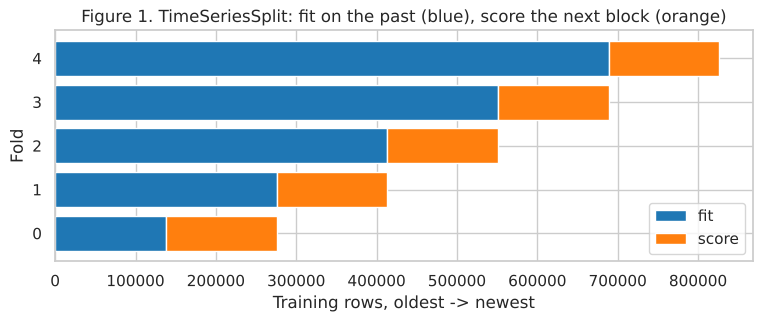

In [8]:
tscv = TimeSeriesSplit(n_splits=5)

fig, ax = plt.subplots(figsize=(9, 3))
for i, (tr_idx, te_idx) in enumerate(tscv.split(X_train)):
    ax.barh(i, len(tr_idx), left=0, color="tab:blue", label="fit" if i == 0 else None)
    ax.barh(i, len(te_idx), left=tr_idx[-1] + 1, color="tab:orange", label="score" if i == 0 else None)
ax.set_xlabel("Training rows, oldest -> newest")
ax.set_ylabel("Fold")
ax.set_title("Figure 1. TimeSeriesSplit: fit on the past (blue), score the next block (orange)")
ax.legend()
save_fig("06_timeseries_cv")
plt.show()

In [9]:
first_fit, first_score = next(iter(tscv.split(X_train)))
print(f"Fold 1 fits on {len(first_fit):,} rows and scores {len(first_score):,} rows right after them.")
print("Every fold's scored block is later in time than its fitting block, so no fold sees the future.")
for i, (tr_idx, te_idx) in enumerate(tscv.split(X_train), start=1):
    assert train["issue_d"].iloc[tr_idx].max() <= train["issue_d"].iloc[te_idx].min()
print("Checked in code: fit dates <= scored dates in all 5 folds.")

Fold 1 fits on 137,769 rows and scores 137,767 rows right after them.
Every fold's scored block is later in time than its fitting block, so no fold sees the future.
Checked in code: fit dates <= scored dates in all 5 folds.


**Table 3.** ROC-AUC per fold, for the baseline and the three models. `B1` is scored on exactly the same folds, so the comparison is fair.

In [10]:
cv_scores = {}
t0 = time.time()

# B1 needs no fitting - score its ranking on each fold's scored block.
cv_scores["B1 sub_grade"] = [roc_auc_score(y_train.iloc[te], train["sub_grade_num"].iloc[te])
                             for _, te in tscv.split(X_train)]

for name, model in candidates.items():
    cv_scores[name] = cross_val_score(make_pipeline(model), X_train, y_train,
                                      cv=tscv, scoring="roc_auc", n_jobs=1)
    print(f"{name:22s} done in {time.time()-t0:5.0f}s")

cv_table = pd.DataFrame(cv_scores, index=[f"fold {i}" for i in range(1, 6)]).T
cv_table["mean"] = cv_table.mean(axis=1)
cv_table["std"] = cv_table.iloc[:, :5].std(axis=1)
cv_table

Logistic regression    done in    49s


Random forest          done in   247s


HistGradientBoosting   done in   310s


,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std
B1 sub_grade,0.670,0.690,0.702,0.711,0.715,0.698,0.018
Logistic regression,0.688,0.713,0.720,0.732,0.734,0.717,0.019
Random forest,0.691,0.713,0.721,0.733,0.735,0.719,0.018
HistGradientBoosting,0.690,0.714,0.723,0.737,0.741,0.721,0.020


In [11]:
mean = cv_table["mean"]
best_cv_name = mean.drop("B1 sub_grade").idxmax()
print(f"Best model by mean CV ROC-AUC: {best_cv_name} ({mean[best_cv_name]:.3f}) vs B1 {mean['B1 sub_grade']:.3f}.")
print(f"Lift over B1: {mean[best_cv_name] - mean['B1 sub_grade']:+.3f} AUC.")
beats = (cv_table.loc[best_cv_name].iloc[:5] > cv_table.loc['B1 sub_grade'].iloc[:5]).sum()
print(f"{best_cv_name} beats B1 in {beats} of 5 folds.")

Best model by mean CV ROC-AUC: HistGradientBoosting (0.721) vs B1 0.698.
Lift over B1: +0.023 AUC.
HistGradientBoosting beats B1 in 5 of 5 folds.


### 8.6 Overfitting check
A model that scores far higher on the rows it was fitted on than on later rows has memorised the past. We fit each model on the fit slice, then compare AUC on the fit slice with AUC on the (later) validation slice.

**Table 4.** Train vs validation ROC-AUC.

In [12]:
fitted_val = {}      # models fitted on the fit slice (used for validation scores and thresholds)
val_scores = {}
rows = []
for name, model in candidates.items():
    pipe = make_pipeline(model).fit(X_fit, y_fit)
    fitted_val[name] = pipe
    val_scores[name] = pipe.predict_proba(X_val)[:, 1]
    fit_auc = roc_auc_score(y_fit, pipe.predict_proba(X_fit)[:, 1])
    val_auc = roc_auc_score(y_val, val_scores[name])
    rows.append((name, fit_auc, val_auc, fit_auc - val_auc))
overfit = pd.DataFrame(rows, columns=["model", "fit_auc", "val_auc", "gap"]).set_index("model")
overfit

,fit_auc,val_auc,gap
model,,,
Logistic regression,0.710,0.736,-0.026
Random forest,0.717,0.737,-0.020
HistGradientBoosting,0.724,0.742,-0.018


In [13]:
print("gap = fit AUC - validation AUC. A clearly positive gap means the model memorised the rows it was fitted on.")
print(overfit["gap"].round(3).to_string())
if (overfit["gap"] > 0.02).any():
    print("At least one model shows a gap above 0.02: it may be overfitting; consider a simpler setting.")
else:
    print("No model has a gap above 0.02, so this check shows no sign of overfitting.")
if (overfit["gap"] < 0).all():
    print("All gaps are negative: every model scores HIGHER on the later validation slice than on the rows it was fitted on. "
          "We did not investigate why; it only tells us the validation slice is not harder than the fit slice.")

gap = fit AUC - validation AUC. A clearly positive gap means the model memorised the rows it was fitted on.
model
Logistic regression    -0.026
Random forest          -0.020
HistGradientBoosting   -0.018
No model has a gap above 0.02, so this check shows no sign of overfitting.
All gaps are negative: every model scores HIGHER on the later validation slice than on the rows it was fitted on. We did not investigate why; it only tells us the validation slice is not harder than the fit slice.


### 8.7 Tuning the boosting model
We try a small grid of two settings and score every combination with `TimeSeriesSplit` on training rows only (3 folds to keep it quick).

- `max_leaf_nodes`: how complex each tree may be (more leaves = more flexible, more overfitting risk)
- `learning_rate`: how big a step each new tree takes (smaller = slower, often more stable)

**Table 5.** Tuning results, sorted by mean CV ROC-AUC. The sklearn default setting (31 leaves, rate 0.1) is one row of the grid.

In [14]:
t0 = time.time()
grid = GridSearchCV(
    make_pipeline(HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_SEED)),
    param_grid={"model__max_leaf_nodes": [15, 31, 63], "model__learning_rate": [0.05, 0.1]},
    cv=TimeSeriesSplit(n_splits=3), scoring="roc_auc", refit=False, n_jobs=1)
grid.fit(X_train, y_train)
print(f"Grid search took {time.time()-t0:.0f}s")

tuning = pd.DataFrame(grid.cv_results_)[["param_model__max_leaf_nodes", "param_model__learning_rate",
                                         "mean_test_score", "std_test_score"]]
tuning.columns = ["max_leaf_nodes", "learning_rate", "mean_cv_auc", "std_cv_auc"]
tuning.sort_values("mean_cv_auc", ascending=False).reset_index(drop=True)

Grid search took 256s


,max_leaf_nodes,learning_rate,mean_cv_auc,std_cv_auc
0,31,0.100,0.723,0.015
1,15,0.100,0.723,0.014
2,63,0.050,0.723,0.015
3,31,0.050,0.723,0.014
4,63,0.100,0.723,0.015
5,15,0.050,0.722,0.014


In [15]:
best_params = grid.best_params_
default_row = tuning[(tuning["max_leaf_nodes"] == 31) & (tuning["learning_rate"] == 0.1)].iloc[0]
print("Best setting:", best_params)
print(f"Best mean CV AUC {grid.best_score_:.4f} vs default setting {default_row['mean_cv_auc']:.4f} "
      f"-> tuning gain {grid.best_score_ - default_row['mean_cv_auc']:+.4f}")
print(f"The spread between the best and worst grid point is {tuning['mean_cv_auc'].max() - tuning['mean_cv_auc'].min():.4f}.")

Best setting: {'model__learning_rate': 0.1, 'model__max_leaf_nodes': 31}
Best mean CV AUC 0.7235 vs default setting 0.7235 -> tuning gain +0.0000
The spread between the best and worst grid point is 0.0014.


In [16]:
# Add the tuned model to the candidates and score it on the same 5 folds as the others.
tuned_params = {k.replace("model__", ""): v for k, v in best_params.items()}
candidates["HistGB (tuned)"] = HistGradientBoostingClassifier(max_iter=100, random_state=RANDOM_SEED, **tuned_params)
cv_scores["HistGB (tuned)"] = cross_val_score(make_pipeline(candidates["HistGB (tuned)"]), X_train, y_train,
                                              cv=tscv, scoring="roc_auc", n_jobs=1)
cv_table.loc["HistGB (tuned)"] = list(cv_scores["HistGB (tuned)"]) + [np.mean(cv_scores["HistGB (tuned)"]),
                                                                       np.std(cv_scores["HistGB (tuned)"], ddof=1)]

best_name = cv_table["mean"].drop("B1 sub_grade").idxmax()
print(cv_table[["mean", "std"]].sort_values("mean", ascending=False))
print()
print(f"Final model chosen on training-only CV: {best_name}")

                      mean   std
HistGB (tuned)       0.721 0.020
HistGradientBoosting 0.721 0.020
Random forest        0.719 0.018
Logistic regression  0.717 0.019
B1 sub_grade         0.698 0.018

Final model chosen on training-only CV: HistGradientBoosting


### 8.8 Does the model still work without Lending Club's own grade and rate?
`grade` and `int_rate` are Lending Club's own risk assessment. If most of our lift comes from them, our model is mostly copying Lending Club. We re-run the cross-validation **without** those two features, using the chosen model, and compare.

**Table 6.** Cross-validated ROC-AUC with and without Lending Club's grade and rate.

In [17]:
own_assessment = ["grade", "int_rate"]
NUMERIC_FULL, CATEGORICAL_FULL = list(NUMERIC), list(CATEGORICAL)

NUMERIC = [c for c in NUMERIC_FULL if c not in own_assessment]
CATEGORICAL = [c for c in CATEGORICAL_FULL if c not in own_assessment]
auc_without = cross_val_score(make_pipeline(candidates[best_name]), X_train, y_train,
                              cv=tscv, scoring="roc_auc", n_jobs=1)
NUMERIC, CATEGORICAL = NUMERIC_FULL, CATEGORICAL_FULL      # restore the full feature set

ablation = pd.DataFrame({
    "setting": ["B1 sub_grade (the incumbent)", f"{best_name}, all features", f"{best_name}, without grade and int_rate"],
    "mean_cv_auc": [cv_table.loc["B1 sub_grade", "mean"], cv_table.loc[best_name, "mean"], auc_without.mean()],
}).set_index("setting")
ablation

,mean_cv_auc
setting,
B1 sub_grade (the incumbent),0.698
"HistGradientBoosting, all features",0.721
"HistGradientBoosting, without grade and int_rate",0.710


In [18]:
without, full, b1 = ablation["mean_cv_auc"].iloc[2], ablation["mean_cv_auc"].iloc[1], ablation["mean_cv_auc"].iloc[0]
print(f"Lending Club's sub-grade alone: {b1:.3f}. Our model with all features: {full:.3f}. Without grade and int_rate: {without:.3f}.")
print(f"Lift over B1 with all features: {full - b1:+.3f}.  Lift over B1 without grade and int_rate: {without - b1:+.3f}.")
print("Action -> report the model with all features as the headline, and state this ablation next to it so readers see "
      "how much of the result depends on Lending Club's own assessment.")

Lending Club's sub-grade alone: 0.698. Our model with all features: 0.721. Without grade and int_rate: 0.710.
Lift over B1 with all features: +0.023.  Lift over B1 without grade and int_rate: +0.013.
Action -> report the model with all features as the headline, and state this ablation next to it so readers see how much of the result depends on Lending Club's own assessment.


### 8.9 Fit the final candidates on **all** training rows
These full-training fits are what we will score on the test set. Nothing in them has seen the test rows.

In [19]:
t0 = time.time()
fitted_full = {}
for name, model in candidates.items():
    fitted_full[name] = make_pipeline(model).fit(X_train, y_train)
    print(f"{name:22s} fitted in {time.time()-t0:5.0f}s")
# the tuned model's validation scores/threshold are needed too
fitted_val["HistGB (tuned)"] = make_pipeline(candidates["HistGB (tuned)"]).fit(X_fit, y_fit)
val_scores["HistGB (tuned)"] = fitted_val["HistGB (tuned)"].predict_proba(X_val)[:, 1]

Logistic regression    fitted in    17s


Random forest          fitted in   111s


HistGradientBoosting   fitted in   134s


HistGB (tuned)         fitted in   156s


## Step 9 - Evaluate

### 9.1 Choose the decision threshold (validation slice only)
A score is turned into a yes/no decision by a threshold. We pick, for each model, the threshold with the highest F1 on the **validation slice**, using the model that was fitted on the fit slice. We do **not** look at test scores to choose it.

*Honest caveat:* F1 treats a missed defaulter and a false alarm as equally bad. A real lender would put dollar costs on each; the dataset has no such costs, so we do not invent them. The curves below show what each threshold trades away.

**Figure 2.** Precision, recall and F1 as the threshold moves (validation slice, chosen model).

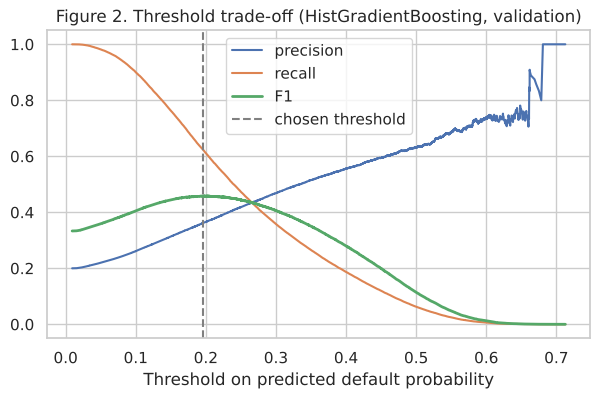

In [20]:
thresholds = {name: best_threshold(y_val, val_scores[name]) for name in candidates}
thresholds["B1 sub_grade"] = thr_b1
thresholds["B0 majority class"] = 1

precision, recall, cuts = precision_recall_curve(y_val, val_scores[best_name])
f1_curve = 2 * precision * recall / (precision + recall + 1e-12)
plt.figure(figsize=(7, 4))
plt.plot(cuts, precision[:-1], label="precision")
plt.plot(cuts, recall[:-1], label="recall")
plt.plot(cuts, f1_curve[:-1], label="F1", linewidth=2)
plt.axvline(thresholds[best_name], color="gray", linestyle="--", label="chosen threshold")
plt.xlabel("Threshold on predicted default probability")
plt.title(f"Figure 2. Threshold trade-off ({best_name}, validation)")
plt.legend()
save_fig("07_threshold_tradeoff")
plt.show()

In [21]:
thr = thresholds[best_name]
chosen = evaluate(y_val, val_scores[best_name], thr)
share_flagged = (val_scores[best_name] >= thr).mean()
print(f"Chosen threshold: {thr:.3f}")
print(f"On validation this flags {share_flagged:.1%} of loans, with precision {chosen['Precision']:.3f} and recall {chosen['Recall']:.3f}.")
print("Action -> keep this threshold fixed from now on; it is applied unchanged to the test set.")

Chosen threshold: 0.196
On validation this flags 34.3% of loans, with precision 0.363 and recall 0.622.
Action -> keep this threshold fixed from now on; it is applied unchanged to the test set.


### 9.2 Open the test set (once)
Every model and both baselines are scored on the test set in this single cell, each with the threshold it got in 9.1. The model we call "final" was chosen in 8.7 by training-only cross-validation, **not** by looking at this table.

**Table 7.** Test-set results.

In [22]:
test_scores = {"B0 majority class": np.zeros(len(y_test)), "B1 sub_grade": test["sub_grade_num"].to_numpy()}
for name in candidates:
    test_scores[name] = fitted_full[name].predict_proba(X_test)[:, 1]

results = pd.DataFrame({name: evaluate(y_test, test_scores[name], thresholds[name]) for name in test_scores}).T
results["final model"] = ["<-- final" if n == best_name else "" for n in results.index]
results

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,final model
B0 majority class,0.500,0.224,0.776,0.000,0.000,0.000,
B1 sub_grade,0.687,0.365,0.643,0.337,0.615,0.436,
Logistic regression,0.704,0.387,0.672,0.360,0.593,0.448,
Random forest,0.704,0.396,0.662,0.354,0.615,0.449,
HistGradientBoosting,0.711,0.404,0.680,0.367,0.594,0.454,<-- final
HistGB (tuned),0.711,0.404,0.680,0.367,0.594,0.454,


In [23]:
r = results.drop(columns="final model").astype(float)
print(f"Test default rate: {y_test.mean():.3f}   |   train default rate: {y_train.mean():.3f}")
print(f"Final model {best_name}: ROC-AUC {r.loc[best_name, 'ROC-AUC']:.3f}, PR-AUC {r.loc[best_name, 'PR-AUC']:.3f}, "
      f"recall {r.loc[best_name, 'Recall']:.3f}, precision {r.loc[best_name, 'Precision']:.3f}")
print(f"B1 sub_grade:            ROC-AUC {r.loc['B1 sub_grade', 'ROC-AUC']:.3f}, PR-AUC {r.loc['B1 sub_grade', 'PR-AUC']:.3f}")
print(f"Lift over B1: {r.loc[best_name, 'ROC-AUC'] - r.loc['B1 sub_grade', 'ROC-AUC']:+.3f} ROC-AUC, "
      f"{r.loc[best_name, 'PR-AUC'] - r.loc['B1 sub_grade', 'PR-AUC']:+.3f} PR-AUC")
print(f"Cross-validated AUC of the final model was {cv_table.loc[best_name, 'mean']:.3f}; "
      f"test AUC is {r.loc[best_name, 'ROC-AUC']:.3f}.")

Test default rate: 0.224   |   train default rate: 0.184
Final model HistGradientBoosting: ROC-AUC 0.711, PR-AUC 0.404, recall 0.594, precision 0.367
B1 sub_grade:            ROC-AUC 0.687, PR-AUC 0.365
Lift over B1: +0.024 ROC-AUC, +0.039 PR-AUC
Cross-validated AUC of the final model was 0.721; test AUC is 0.711.


### 9.3 Is the lift over B1 real, or noise?
The test set is one sample of loans. If we drew a different sample, the lift might be a bit different. The **bootstrap** estimates this: resample the test rows with replacement 100 times, recompute both AUCs each time, and look at the spread of the difference. If the 95% range excludes 0, the lift is unlikely to be luck.

In [24]:
rng = np.random.default_rng(RANDOM_SEED)
y_arr = y_test.to_numpy()
model_score, b1_score = test_scores[best_name], test_scores["B1 sub_grade"]

lifts = []
for _ in range(100):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    lifts.append(roc_auc_score(y_arr[idx], model_score[idx]) - roc_auc_score(y_arr[idx], b1_score[idx]))
low, high = np.percentile(lifts, [2.5, 97.5])

print(f"AUC lift over B1: {np.mean(lifts):+.4f}   95% bootstrap range: [{low:+.4f}, {high:+.4f}]")
print("The range excludes 0 -> the lift is not luck." if low > 0 else "The range includes 0 -> we cannot claim a lift.")

AUC lift over B1: +0.0240   95% bootstrap range: [+0.0230, +0.0248]
The range excludes 0 -> the lift is not luck.


### 9.4 ROC and precision-recall curves

**Figure 3.** Left: ROC curves. Right: precision-recall curves. Test set, all models and B1.

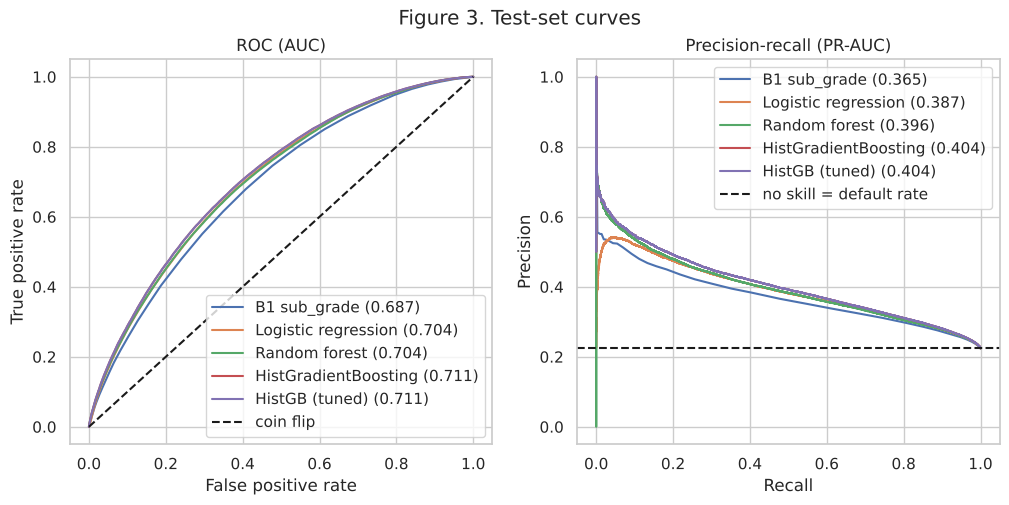

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name in test_scores:
    if name == "B0 majority class":
        continue
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax[0].plot(fpr, tpr, label=f"{name} ({r.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, test_scores[name])
    ax[1].plot(rec, prec, label=f"{name} ({r.loc[name, 'PR-AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", label="coin flip")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].set_title("ROC (AUC)")
ax[1].axhline(y_test.mean(), color="k", linestyle="--", label="no skill = default rate")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Precision-recall (PR-AUC)")
ax[0].legend(); ax[1].legend()
fig.suptitle("Figure 3. Test-set curves")
save_fig("08_roc_pr_curves")
plt.show()

In [26]:
order = r.drop(["B0 majority class"])["ROC-AUC"].sort_values(ascending=False)
print("Test ROC-AUC ranking:", ", ".join(f"{n} {v:.3f}" for n, v in order.items()))
gap_models = order.drop("B1 sub_grade")
print(f"Spread among the four models: {gap_models.max() - gap_models.min():.3f} AUC. "
      f"Spread between the best model and B1: {order.iloc[0] - order['B1 sub_grade']:.3f}.")
print("Action -> the choice among our models matters less than the choice between 'model' and 'B1'; "
      "keep the CV-chosen model rather than switching after seeing this plot.")

Test ROC-AUC ranking: HistGB (tuned) 0.711, HistGradientBoosting 0.711, Logistic regression 0.704, Random forest 0.704, B1 sub_grade 0.687
Spread among the four models: 0.007 AUC. Spread between the best model and B1: 0.024.
Action -> the choice among our models matters less than the choice between 'model' and 'B1'; keep the CV-chosen model rather than switching after seeing this plot.


### 9.5 What kinds of mistakes does the final model make?

**Figure 4.** Confusion matrix of the final model on the test set, at the threshold from 9.1.

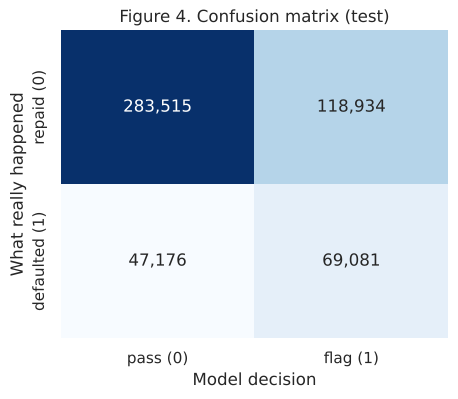

In [27]:
flagged_test = (test_scores[best_name] >= thresholds[best_name]).astype(int)
cm = confusion_matrix(y_test, flagged_test)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["pass (0)", "flag (1)"], yticklabels=["repaid (0)", "defaulted (1)"])
plt.xlabel("Model decision"); plt.ylabel("What really happened")
plt.title("Figure 4. Confusion matrix (test)")
save_fig("09_confusion_matrix")
plt.show()

In [28]:
tn, fp, fn, tp = cm.ravel()
print(f"Caught {tp:,} of {tp+fn:,} defaulters (recall {tp/(tp+fn):.1%}); missed {fn:,}.")
print(f"Flagged {fp:,} good borrowers by mistake: {fp/(fp+tn):.1%} of all borrowers who repaid.")
print(f"Of the {tp+fp:,} loans flagged, {tp/(tp+fp):.1%} really defaulted (precision), versus a base default rate of {y_test.mean():.1%}.")
print("Action -> the lender must decide whether missing a defaulter or rejecting a good borrower costs more; "
      "that decides whether to move the threshold in Figure 2.")

Caught 69,081 of 116,257 defaulters (recall 59.4%); missed 47,176.
Flagged 118,934 good borrowers by mistake: 29.6% of all borrowers who repaid.
Of the 188,015 loans flagged, 36.7% really defaulted (precision), versus a base default rate of 22.4%.
Action -> the lender must decide whether missing a defaulter or rejecting a good borrower costs more; that decides whether to move the threshold in Figure 2.


### 9.6 Does a predicted 20% mean 20%? (calibration)
We sort test loans by predicted probability, cut them into ten equal groups, and compare the average prediction in each group with the share that really defaulted. If the model is well calibrated the points sit on the diagonal.

**Figure 5.** Predicted vs actual default rate by predicted-risk decile (test set).

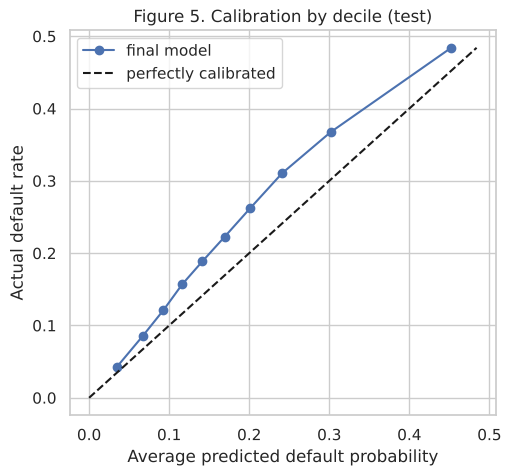

In [29]:
calib = pd.DataFrame({"pred": test_scores[best_name], "actual": y_arr})
calib["decile"] = pd.qcut(calib["pred"], 10, labels=False, duplicates="drop")
calib = calib.groupby("decile").agg(predicted=("pred", "mean"), actual=("actual", "mean"))

plt.figure(figsize=(5.5, 5))
plt.plot(calib["predicted"], calib["actual"], marker="o", label="final model")
top = max(calib.max())
plt.plot([0, top], [0, top], "k--", label="perfectly calibrated")
plt.xlabel("Average predicted default probability"); plt.ylabel("Actual default rate")
plt.title("Figure 5. Calibration by decile (test)")
plt.legend()
save_fig("10_calibration")
plt.show()

In [30]:
mean_pred, mean_actual = calib["predicted"].mean(), y_test.mean()
print(f"Average predicted probability on test: {mean_pred:.3f}; actual default rate: {mean_actual:.3f}.")
direction = "under-predicts" if mean_pred < mean_actual else "over-predicts"
print(f"The model {direction} default on the test period by {abs(mean_actual - mean_pred):.3f} on average.")
print(f"Training default rate was {y_train.mean():.3f} and test is {mean_actual:.3f}: the model learned from an older period with a different default rate.")
print("Action -> use the score to RANK applicants; if exact probabilities are needed, re-calibrate on recent loans.")

Average predicted probability on test: 0.182; actual default rate: 0.224.
The model under-predicts default on the test period by 0.042 on average.
Training default rate was 0.184 and test is 0.224: the model learned from an older period with a different default rate.
Action -> use the score to RANK applicants; if exact probabilities are needed, re-calibrate on recent loans.


### 9.7 How much does out-of-time testing matter?
We repeat the experiment with an ordinary **random** 80/20 split of all labelled loans (stratified, `random_state=42`), using the same model type and settings. If testing on later loans is harder than on randomly chosen loans, the out-of-time AUC should be **lower**. If it is not, something is wrong and we must investigate rather than report it.

This random-split number is a reference only; it is not our headline result.

In [31]:
all_labelled = pd.concat([train, test]).reset_index(drop=True)
tr_idx, te_idx = train_test_split(np.arange(len(all_labelled)), test_size=0.2, stratify=all_labelled["default"],
                                  random_state=RANDOM_SEED)
random_pipe = make_pipeline(candidates[best_name]).fit(all_labelled.loc[tr_idx, FEATURE_COLS], all_labelled.loc[tr_idx, "default"])
random_auc = roc_auc_score(all_labelled.loc[te_idx, "default"], random_pipe.predict_proba(all_labelled.loc[te_idx, FEATURE_COLS])[:, 1])
oot_auc = r.loc[best_name, "ROC-AUC"]

print(f"Random split ROC-AUC:        {random_auc:.3f}")
print(f"Out-of-time (our test) AUC:  {oot_auc:.3f}")
print(f"Difference (random - out-of-time): {random_auc - oot_auc:+.3f}")
print("As expected, out-of-time is lower." if random_auc > oot_auc else
      "WARNING: out-of-time is NOT lower than random. Investigate before reporting.")

Random split ROC-AUC:        0.720
Out-of-time (our test) AUC:  0.711
Difference (random - out-of-time): +0.009
As expected, out-of-time is lower.


### 9.8 Where is the model strong or weak? (error analysis)
**Figure 6.** Test ROC-AUC by issue year, final model vs B1, with the share of loans that are unresolved in that year (from notebook 02, Table 4).

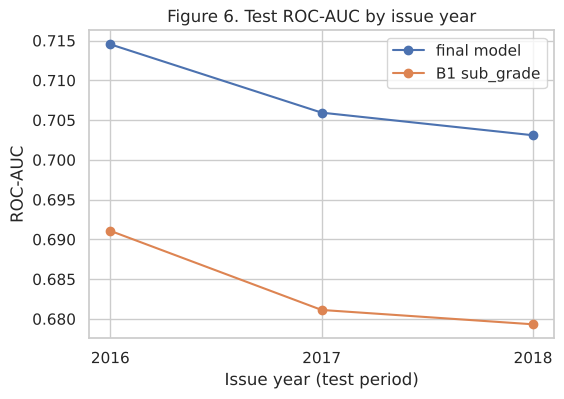

,loans,actual_default_rate,mean_predicted,model_auc,b1_auc
year,,,,,
2016,293095,0.233,0.181,0.715,0.691
2017,169300,0.231,0.185,0.706,0.681
2018,56311,0.157,0.172,0.703,0.679


In [32]:
test_eval = test[["issue_d", "default", "grade"]].copy()
test_eval["pred"] = test_scores[best_name]
test_eval["b1"] = test_scores["B1 sub_grade"]
test_eval["year"] = test_eval["issue_d"].dt.year

by_year = test_eval.groupby("year").apply(lambda g: pd.Series({
    "loans": len(g), "actual_default_rate": g["default"].mean(), "mean_predicted": g["pred"].mean(),
    "model_auc": roc_auc_score(g["default"], g["pred"]), "b1_auc": roc_auc_score(g["default"], g["b1"])}),
    include_groups=False)

plt.figure(figsize=(6, 4))
plt.plot(by_year.index.astype(str), by_year["model_auc"], marker="o", label="final model")
plt.plot(by_year.index.astype(str), by_year["b1_auc"], marker="o", label="B1 sub_grade")
plt.ylabel("ROC-AUC"); plt.xlabel("Issue year (test period)")
plt.title("Figure 6. Test ROC-AUC by issue year")
plt.legend()
save_fig("11_auc_by_year")
plt.show()
by_year["loans"] = by_year["loans"].astype(int)
by_year

In [33]:
by_grade = test_eval.groupby("grade").apply(lambda g: pd.Series({
    "loans": len(g), "actual_default_rate": g["default"].mean(),
    "model_auc_within_grade": roc_auc_score(g["default"], g["pred"])}), include_groups=False)
by_grade["loans"] = by_grade["loans"].astype(int)
print("Table 8. Does the model still rank borrowers *within* a single Lending Club grade?")
print(by_grade.to_string())
print()
print(f"Model AUC by year ranges from {by_year['model_auc'].min():.3f} ({by_year['model_auc'].idxmin()}) "
      f"to {by_year['model_auc'].max():.3f} ({by_year['model_auc'].idxmax()}).")
print(f"Lift over B1 per year: " + ", ".join(f"{y}: {d:+.3f}" for y, d in (by_year['model_auc'] - by_year['b1_auc']).items()))
print(f"Within-grade AUC runs from {by_grade['model_auc_within_grade'].min():.3f} (grade {by_grade['model_auc_within_grade'].idxmin()}) "
      f"to {by_grade['model_auc_within_grade'].max():.3f} (grade {by_grade['model_auc_within_grade'].idxmax()}); "
      "values above 0.5 mean the model separates borrowers inside one grade (it can use int_rate, which still varies within a grade).")
print("Action -> in notebook 04 we track AUC over time and treat a fall towards B1 as the signal to retrain.")

Table 8. Does the model still rank borrowers *within* a single Lending Club grade?
        loans  actual_default_rate  model_auc_within_grade
grade                                                     
A       88660                0.068                   0.660
B      151231                0.155                   0.616
C      156452                0.254                   0.610
D       74951                0.342                   0.602
E       31780                0.418                   0.606
F       11365                0.504                   0.603
G        4267                0.536                   0.595

Model AUC by year ranges from 0.703 (2018) to 0.715 (2016).
Lift over B1 per year: 2016: +0.023, 2017: +0.025, 2018: +0.024
Within-grade AUC runs from 0.595 (grade G) to 0.660 (grade A); values above 0.5 mean the model separates borrowers inside one grade (it can use int_rate, which still varies within a grade).
Action -> in notebook 04 we track AUC over time and treat a fall toward

## Step 10 - Explain the model

### 10.1 Which features matter? (permutation importance)
Shuffle one feature at a time on the validation slice and see how much the ROC-AUC drops. A big drop means the model relied on that feature. We use the model fitted on the fit slice and a random 30,000-row sample of the validation slice to keep this quick.

**Figure 7.** Permutation importance, top 12 features.

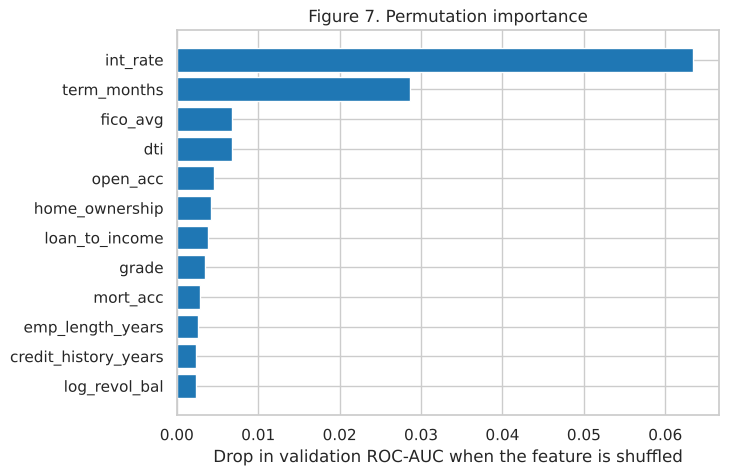

In [34]:
val_sample = val_part.sample(min(30000, len(val_part)), random_state=RANDOM_SEED)
perm = permutation_importance(fitted_val[best_name], val_sample[FEATURE_COLS], val_sample["default"],
                              scoring="roc_auc", n_repeats=3, random_state=RANDOM_SEED, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=FEATURE_COLS).sort_values(ascending=False)

top12 = importance.head(12).iloc[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top12.index, top12.values, color="tab:blue")
plt.xlabel("Drop in validation ROC-AUC when the feature is shuffled")
plt.title("Figure 7. Permutation importance")
save_fig("12_permutation_importance")
plt.show()

In [35]:
print("Top 5:", ", ".join(f"{n} ({v:.4f})" for n, v in importance.head(5).items()))
useless = importance[importance < 0.0005].index.tolist()
print(f"Features whose shuffling changes AUC by less than 0.0005: {useless if useless else 'none'}")
print("Action -> features with ~0 importance add complexity but no accuracy; they are candidates to drop in a future version.")

Top 5: int_rate (0.0635), term_months (0.0286), fico_avg (0.0067), dti (0.0067), open_acc (0.0046)
Features whose shuffling changes AUC by less than 0.0005: ['verification_status', 'purpose', 'installment', 'pub_rec', 'delinq_2yrs', 'pub_rec_bankruptcies', 'application_type']
Action -> features with ~0 importance add complexity but no accuracy; they are candidates to drop in a future version.


### 10.2 Which direction does each feature push? (logistic regression coefficients)
Logistic regression gives one number per feature. Because the numeric features were standardised, coefficients are comparable: a **positive** value raises the predicted default risk, a **negative** value lowers it.

**Table 9.** Largest logistic-regression coefficients (full training fit).

In [36]:
lr_pipe = fitted_full["Logistic regression"]
names = lr_pipe.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lr_pipe.named_steps["model"].coef_[0], index=names).sort_values()
top_coef = pd.concat([coef.head(6), coef.tail(6)]).to_frame("coefficient")
top_coef

,coefficient
cat__grade_A,-0.948
cat__grade_B,-0.470
cat__purpose_wedding,-0.392
cat__application_type_Individual,-0.358
cat__home_ownership_MORTGAGE,-0.295
cat__verification_status_Not Verified,-0.244
num__installment,0.151
cat__grade_E,0.226
cat__grade_F,0.300
cat__purpose_small_business,0.323


In [37]:
print("Pushes risk UP most:  ", ", ".join(coef.tail(3).index[::-1].str.replace("num__", "").str.replace("cat__", "")))
print("Pushes risk DOWN most:", ", ".join(coef.head(3).index.str.replace("num__", "").str.replace("cat__", "")))
print("Reading: for a numeric feature, one standard deviation more changes the log-odds of default by its coefficient; "
      "for a one-hot column (cat__...), it is the effect of belonging to that category. Others held fixed.")

Pushes risk UP most:   grade_G, term_months, purpose_small_business
Pushes risk DOWN most: grade_A, grade_B, purpose_wedding
Reading: for a numeric feature, one standard deviation more changes the log-odds of default by its coefficient; for a one-hot column (cat__...), it is the effect of belonging to that category. Others held fixed.


### 10.3 Shape of the effect (partial dependence)
Partial dependence shows the model's average prediction as one feature is moved across its range while everything else is left as it is. We plot the three most important numeric features from Figure 7.

**Figure 8.** Partial dependence of the final model.

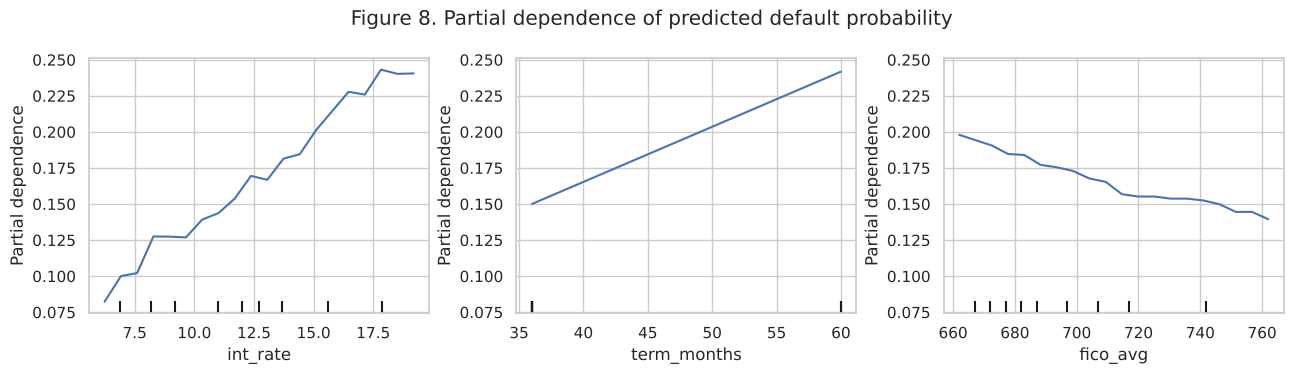

In [38]:
top_numeric = [f for f in importance.index if f in NUMERIC][:3]
pd_sample = val_sample.sample(min(10000, len(val_sample)), random_state=RANDOM_SEED)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
display = PartialDependenceDisplay.from_estimator(fitted_val[best_name], pd_sample[FEATURE_COLS], top_numeric,
                                                  kind="average", grid_resolution=20, ax=ax)
fig.suptitle("Figure 8. Partial dependence of predicted default probability")
fig.tight_layout()
save_fig("13_partial_dependence")
plt.show()

In [39]:
for feature, line in zip(top_numeric, display.lines_.ravel()):
    y_values = line.get_ydata()
    trend = "increases" if y_values[-1] > y_values[0] else "decreases"
    print(f"{feature}: predicted risk {trend} from {y_values[0]:.3f} (low end) to {y_values[-1]:.3f} (high end)")
print("Action -> a curve that is flat over most of its range means that feature only matters at the extremes.")

int_rate: predicted risk increases from 0.082 (low end) to 0.241 (high end)
term_months: predicted risk increases from 0.150 (low end) to 0.242 (high end)
fico_avg: predicted risk decreases from 0.198 (low end) to 0.139 (high end)
Action -> a curve that is flat over most of its range means that feature only matters at the extremes.


## Conclusions

### Results summary
All numbers below are read from the objects computed above.

In [40]:
summary = pd.DataFrame({
    "item": ["Final model", "Cross-validated ROC-AUC (train)", "Test ROC-AUC", "Test ROC-AUC of B1 (Lending Club sub_grade)",
             "Lift over B1 (test)", "95% bootstrap range of lift", "Random-split AUC (reference)",
             "Test recall at chosen threshold", "Test precision at chosen threshold"],
    "value": [best_name, f"{cv_table.loc[best_name, 'mean']:.3f}", f"{r.loc[best_name, 'ROC-AUC']:.3f}",
              f"{r.loc['B1 sub_grade', 'ROC-AUC']:.3f}", f"{r.loc[best_name, 'ROC-AUC'] - r.loc['B1 sub_grade', 'ROC-AUC']:+.3f}",
              f"[{low:+.3f}, {high:+.3f}]", f"{random_auc:.3f}",
              f"{r.loc[best_name, 'Recall']:.3f}", f"{r.loc[best_name, 'Precision']:.3f}"]}).set_index("item")
summary

,value
item,
Final model,HistGradientBoosting
Cross-validated ROC-AUC (train),0.721
Test ROC-AUC,0.711
Test ROC-AUC of B1 (Lending Club sub_grade),0.687
Lift over B1 (test),+0.024
95% bootstrap range of lift,"[+0.023, +0.025]"
Random-split AUC (reference),0.720
Test recall at chosen threshold,0.594
Test precision at chosen threshold,0.367


### Limitations (these stay in the write-up)

1. **`issue_d` stands in for the application date.** The data records when the loan was *issued*, not when the borrower applied. Features are therefore dated slightly later than a real scorecard would see them.
2. **Unfinished loans bias the test labels.** We keep only `Fully Paid` and `Charged Off`. Notebook 02, Table 4, shows how small a share of the late test years is resolved, so the test default rate is not the true rate for those years.
3. **Only accepted loans are in the data.** The model estimates risk *given that Lending Club approved the loan*, not for everyone who applied.
4. **The world moves.** Section 9.6 shows the gap between predicted and actual default in the test period, and Figure 6 shows AUC by year. A deployed model must be re-fitted regularly; notebook 04 sets a simple rule for when.
5. **Costs are unknown.** The threshold maximises F1 because the dataset has no dollar cost for a missed default or a rejected good loan.
6. **No fairness analysis.** The data has no protected attributes, so we cannot check for discrimination. We make no claim about it.

### Save what notebook 04 needs

In [41]:
# Save the final fitted pipeline (fitted on ALL training rows only), its threshold, and the metric table.
joblib.dump(fitted_full[best_name], ARTIFACTS / "model.joblib")
results.drop(columns="final model").to_csv(ARTIFACTS / "metrics.csv")
(ARTIFACTS / "threshold.json").write_text(json.dumps({"model": best_name, "threshold": float(thresholds[best_name]),
                                                      "rule": "max F1 on validation slice (last 20% of training rows)"}, indent=2))
cv_table.to_csv(ARTIFACTS / "cv_results.csv")
print("Saved model.joblib, metrics.csv, cv_results.csv, threshold.json in", ARTIFACTS.resolve())

Saved model.joblib, metrics.csv, cv_results.csv, threshold.json in /home/user/Lending-Club/artifacts
